# DS605: Fundamentals of Machine Learning
## Lab Assignment 7: Image Representation, PCA, Eigenfaces and Face Recognition

**Dataset:** AT&T Database of Faces (ORL): 40 subjects, 10 grayscale images each, 112 x 92 pixels.

**Objective.** Represent face images numerically, reduce their dimensionality with PCA (eigenfaces), recognise faces by nearest-neighbour matching in the reduced space, and compare this similarity-based baseline with traditional machine-learning classifiers.

**Workflow followed in this notebook**

Images -> Grayscale Pixel Matrix -> Flatten -> Mean Centering -> PCA / SVD -> Explained Variance -> Eigenfaces -> Reduced Representation -> Reconstruction -> Similarity Matching -> ML Classification

**Implementation constraint.** All PCA and eigenface computations (mean face, centering, covariance, eigendecomposition, SVD, projection, reconstruction, distances) are written with NumPy linear algebra. Pillow is used only to read the image files. Scikit-learn is used only in Part D for the traditional classifiers and cross-validation.

### Libraries used and why

| Library | Used for | Reason |
|---|---|---|
| NumPy | Image matrices, mean centering, `eigh`, `svd`, projection, distances | Required by the assignment; provides fast, well-tested LAPACK routines |
| Pillow (PIL) | Reading `.pgm` files | Reads the portable graymap format natively; used for file input only |
| Matplotlib | All figures | Standard plotting library; figures are also saved to `figures/` |
| pandas | Result tables | Readable tabular output and CSV export to `results/` |
| scikit-learn | Part D only: KNN, Logistic Regression, SVM, pipelines, cross-validation | Allowed for the final traditional-ML comparison |

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

SEED = 42                          # single seed used everywhere for reproducibility
DATA_DIR = Path("data/att_faces")  # folder containing s1 ... s40
FIG_DIR = Path("figures")
RES_DIR = Path("results")
FIG_DIR.mkdir(exist_ok=True)
RES_DIR.mkdir(exist_ok=True)

plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight",
                     "image.cmap": "gray", "axes.grid": False})
np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", None)
print("NumPy", np.__version__, "| pandas", pd.__version__)

NumPy 2.5.1 | pandas 3.0.5


---
## Part A: Image Representation

### A.1 Reading the images as grayscale pixel matrices
The dataset is organised as one folder per subject (`s1` ... `s40`), each holding ten `.pgm` files. Each file is opened with Pillow, converted to mode `"L"` (8-bit single-channel grayscale, a safeguard in case any file is not already grayscale) and turned into a NumPy array. Folders and files are sorted **numerically** so that `s10` does not come before `s2`; this keeps the order of images and labels deterministic.

In [2]:
def load_orl(root):
    # Return images (n, h, w) uint8, subject labels (n,), and relative file paths (n,).
    root = Path(root)
    if not root.exists():
        raise FileNotFoundError(f"Dataset not found at {root.resolve()}. See README for setup.")
    subject_dirs = sorted((d for d in root.iterdir() if d.is_dir() and d.name.startswith("s")),
                          key=lambda d: int(d.name[1:]))
    images, labels, paths = [], [], []
    for d in subject_dirs:
        for f in sorted(d.glob("*.pgm"), key=lambda f: int(f.stem)):
            images.append(np.asarray(Image.open(f).convert("L")))
            labels.append(int(d.name[1:]))
            paths.append(f"{d.name}/{f.name}")
    return np.stack(images), np.array(labels), np.array(paths)

images, labels, paths = load_orl(DATA_DIR)
n_images, IMG_H, IMG_W = images.shape
print(f"Images loaded      : {n_images}")
print(f"Image matrix shape : {IMG_H} rows x {IMG_W} columns")
print(f"Subjects           : {len(np.unique(labels))}")
print(f"Images per subject : {np.unique(np.bincount(labels)[1:])}")

Images loaded      : 400
Image matrix shape : 112 rows x 92 columns
Subjects           : 40
Images per subject : [10]


### A.2 Inspecting dimensions and intensity values
Each image is a 112 x 92 matrix of unsigned 8-bit integers, so every entry is an intensity in [0, 255] (0 = black, 255 = white). Below we print a small block of one matrix, global intensity statistics, and visualise the data.

In [3]:
print("Data type :", images.dtype)
print("Top-left 6 x 6 block of the first image (subject 1):")
print(images[0, :6, :6])

stats = pd.DataFrame({
    "min": [images.min()], "max": [images.max()],
    "mean": [images.mean()], "std": [images.std()],
    "pixels per image": [IMG_H * IMG_W]})
stats

Data type : uint8
Top-left 6 x 6 block of the first image (subject 1):
[[48 49 45 47 49 57]
 [45 52 39 46 56 45]
 [45 50 42 51 51 45]
 [49 46 47 47 50 47]
 [46 46 47 48 48 44]
 [47 45 48 51 44 35]]


,min,max,mean,std,pixels per image
0,0,251,112.6313,49.9247,10304


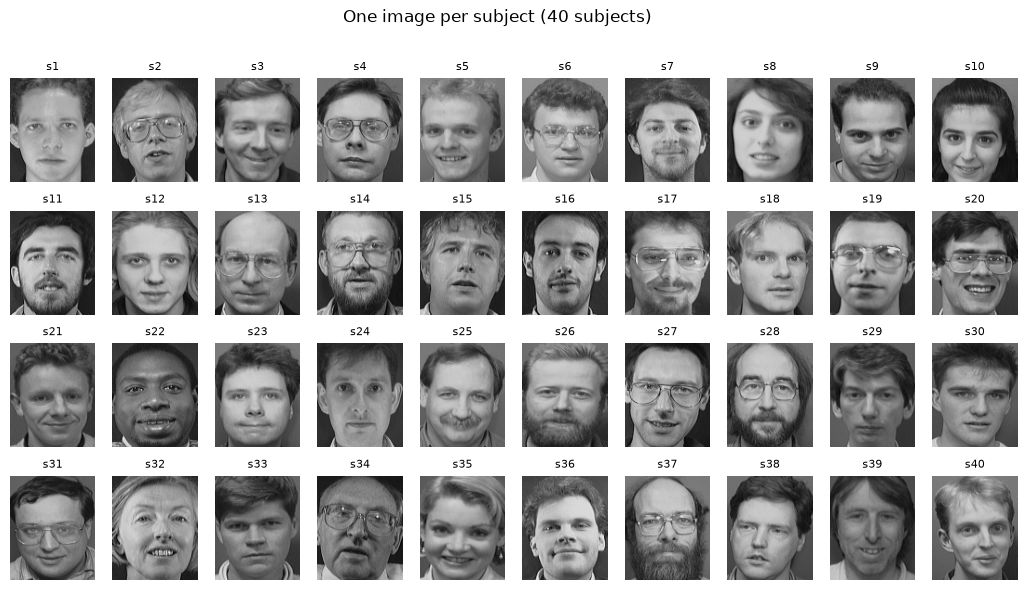

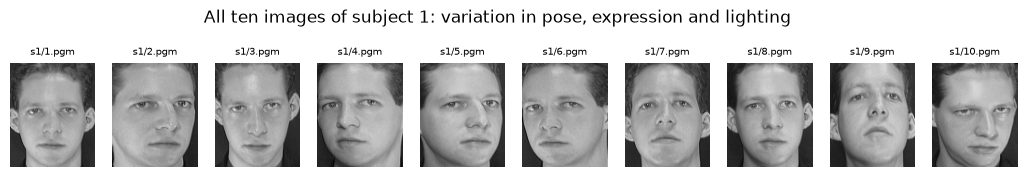

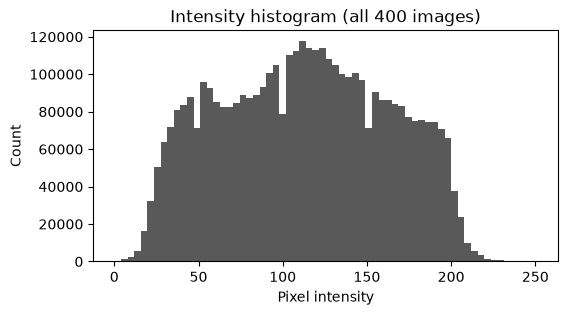

In [4]:
fig, axes = plt.subplots(4, 10, figsize=(13, 6.6))
for ax, s in zip(axes.ravel(), range(1, 41)):
    ax.imshow(images[np.flatnonzero(labels == s)[0]], vmin=0, vmax=255)
    ax.set_title(f"s{s}", fontsize=8); ax.axis("off")
fig.suptitle("One image per subject (40 subjects)")
fig.savefig(FIG_DIR / "A_one_face_per_subject.png"); plt.show()

fig, axes = plt.subplots(1, 10, figsize=(13, 1.9))
for ax, i in zip(axes, np.flatnonzero(labels == 1)):
    ax.imshow(images[i], vmin=0, vmax=255); ax.set_title(paths[i], fontsize=7); ax.axis("off")
fig.suptitle("All ten images of subject 1: variation in pose, expression and lighting", y=1.05)
fig.savefig(FIG_DIR / "A_subject1_variation.png"); plt.show()

plt.figure(figsize=(6, 3))
plt.hist(images.ravel(), bins=64, color="0.35")
plt.xlabel("Pixel intensity"); plt.ylabel("Count"); plt.title("Intensity histogram (all 400 images)")
plt.savefig(FIG_DIR / "A_intensity_histogram.png"); plt.show()

**Observation.** Faces are roughly centred and aligned, with variation in pose, expression, glasses and lighting. Intensities use most of the 0-255 range, so no contrast stretching is needed.

### A.3 Flattening images into feature vectors
PCA works on vectors, so each 112 x 92 matrix is flattened row by row (NumPy `reshape`, C order) into a vector of 112 x 92 = 10,304 values. Stacking all vectors gives the **image matrix** $X \in \mathbb{R}^{400 \times 10304}$: one row per image, one column per pixel, with a separate label vector $y$.

Two choices made here:
- **Scale to [0, 1] (divide by 255).** This is a uniform scaling, so it does not change the principal directions or nearest neighbours; it only keeps numbers small and makes reconstruction errors easy to interpret.
- **float64.** Gives full precision for the eigendecomposition and SVD.

Flattening is lossless: reshaping a row back to 112 x 92 recovers the original image exactly.

In [5]:
X = images.reshape(n_images, -1).astype(np.float64) / 255.0
y = labels.copy()
D_PIX = X.shape[1]

assert np.array_equal((X[0] * 255).round().astype(np.uint8).reshape(IMG_H, IMG_W), images[0])
print("Image matrix X :", X.shape, "| label vector y :", y.shape)

# Image matrix with subject labels (first rows, a few pixel columns shown)
preview = pd.DataFrame(X[:, [0, 1, 2, D_PIX // 2, D_PIX - 1]],
                       columns=["px_0", "px_1", "px_2", f"px_{D_PIX // 2}", f"px_{D_PIX - 1}"])
preview.insert(0, "file", paths); preview["subject"] = y
preview.iloc[[0, 1, 10, 11, 399]]

Image matrix X : (400, 10304) | label vector y : (400,)


,file,px_0,px_1,px_2,px_5152,px_10303,subject
0,s1/1.pgm,0.1882,0.1922,0.1765,0.4471,0.1804,1
1,s1/2.pgm,0.2353,0.2353,0.2431,0.6275,0.1333,1
10,s2/1.pgm,0.1373,0.1412,0.1451,0.2000,0.5608,2
11,s2/2.pgm,0.1451,0.1373,0.1373,0.1451,0.1098,2
399,s40/10.pgm,0.4902,0.4863,0.4863,0.4431,0.1333,40


### A.4 Reproducible train-test split
The split is **stratified per subject**: for every subject, its 10 images are shuffled with a fixed-seed random generator, 7 go to training and 3 to testing. This guarantees every subject appears in both sets (a requirement for closed-set recognition) and gives a 280 / 120 split. It is implemented with NumPy so that Scikit-learn is not used before Part D. The indices are saved so the exact split can be reused.

In [6]:
def stratified_split(labels, n_train_per_class, seed):
    rng = np.random.default_rng(seed)
    train_idx, test_idx = [], []
    for c in np.unique(labels):
        idx = rng.permutation(np.flatnonzero(labels == c))
        train_idx.extend(idx[:n_train_per_class])
        test_idx.extend(idx[n_train_per_class:])
    return np.sort(train_idx), np.sort(test_idx)

N_TRAIN_PER_SUBJECT = 7
train_idx, test_idx = stratified_split(y, N_TRAIN_PER_SUBJECT, SEED)
X_train, y_train = X[train_idx], y[train_idx]
X_test,  y_test  = X[test_idx],  y[test_idx]
np.savez(RES_DIR / "split_indices.npz", train_idx=train_idx, test_idx=test_idx, seed=SEED)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Train images per subject:", np.unique(np.bincount(y_train)[1:]))
print("Test images per subject :", np.unique(np.bincount(y_test)[1:]))
print("Overlap between sets    :", len(np.intersect1d(train_idx, test_idx)))

Train: (280, 10304) | Test: (120, 10304)
Train images per subject: [7]
Test images per subject : [3]
Overlap between sets    : 0


---
## Part B: PCA, Eigenfaces and Compression

### B.1 Mean face and centering
PCA describes variation **around the mean**, so the mean face $\mu$ is subtracted from every training image: $X_c = X_{train} - \mathbf{1}\mu^\top$. The mean is computed from the **training set only**; test images are later centred with this same $\mu$, so no information from the test set leaks into the model.

Max |column mean| after centering: 1.1926967350258824e-15


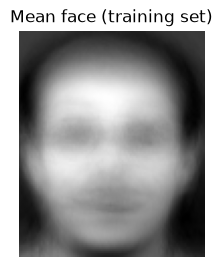

In [7]:
mean_face = X_train.mean(axis=0)
Xc = X_train - mean_face
n_train = Xc.shape[0]
print("Max |column mean| after centering:", np.abs(Xc.mean(axis=0)).max())

plt.figure(figsize=(2.4, 3)); plt.imshow(mean_face.reshape(IMG_H, IMG_W)); plt.axis("off")
plt.title("Mean face (training set)")
plt.savefig(FIG_DIR / "B_mean_face.png"); plt.show()

### B.2 Principal directions: covariance eigendecomposition vs SVD

**Approach 1: covariance eigendecomposition.** The principal directions are the eigenvectors of the covariance matrix $C = \frac{1}{n-1} X_c^\top X_c$. Here $C$ would be 10,304 x 10,304 (about 850 MB in float64, and $O(d^3)$ to decompose). Because $n = 280 \ll d$, $C$ has rank at most $n-1 = 279$, so we use the equivalent **Gram-matrix trick** of Turk and Pentland (1991):

$$G = \tfrac{1}{n-1} X_c X_c^\top \ (280 \times 280),\qquad G v = \lambda v \;\Rightarrow\; C\,(X_c^\top v) = \lambda\,(X_c^\top v).$$

So $C$ and $G$ share their non-zero eigenvalues, and the eigenfaces are $u = X_c^\top v / \lVert X_c^\top v \rVert$. `np.linalg.eigh` is used because $G$ is symmetric: it guarantees real eigenvalues and orthonormal eigenvectors and is faster and more stable than the general `eig`. Only the $n-1$ non-zero eigenvalues are kept (centering removes one degree of freedom).

**Approach 2: SVD.** The economy SVD $X_c = U S V^\top$ gives the principal directions directly as the rows of $V^\top$, with eigenvalues $\lambda_i = s_i^2/(n-1)$. SVD works on $X_c$ itself and never forms $X_c^\top X_c$, which would square the condition number, so it is the numerically preferred method.

In [8]:
# Approach 1: covariance eigendecomposition via the n x n Gram matrix
t0 = time.perf_counter()
G = (Xc @ Xc.T) / (n_train - 1)
evals_g, evecs_g = np.linalg.eigh(G)               # ascending order
order = np.argsort(evals_g)[::-1]                  # sort descending
evals_g, evecs_g = evals_g[order], evecs_g[:, order]
rank = int(np.sum(evals_g > 1e-10 * evals_g[0]))   # number of non-zero eigenvalues
evals_cov = evals_g[:rank]
U_cov = Xc.T @ evecs_g[:, :rank]                   # map back to pixel space (d x rank)
U_cov /= np.linalg.norm(U_cov, axis=0, keepdims=True)
t_cov = time.perf_counter() - t0

# Approach 2: SVD of the centred data
t0 = time.perf_counter()
U_s, S, Vt = np.linalg.svd(Xc, full_matrices=False)
evals_svd = (S**2 / (n_train - 1))[:rank]
U_svd = Vt[:rank].T                                # d x rank
t_svd = time.perf_counter() - t0

# Check that U_cov really holds eigenvectors of C, without ever building C
CU = Xc.T @ (Xc @ U_cov[:, :10]) / (n_train - 1)
resid = np.linalg.norm(CU - U_cov[:, :10] * evals_cov[:10], axis=0) / evals_cov[:10]
print(f"Numerical rank: {rank} (= n_train - 1)")
print(f"Max relative residual ||Cu - lambda u|| / lambda (top 10): {resid.max():.2e}")

Numerical rank: 279 (= n_train - 1)
Max relative residual ||Cu - lambda u|| / lambda (top 10): 2.62e-15


,Approach,Matrix decomposed,Time (s),Components obtained
0,Covariance eigendecomposition (Gram trick),G: 280 x 280,0.0774,279
1,SVD of centred data,Xc: 280 x 10304,0.4119,279


Max relative eigenvalue difference (all 279)    : 1.08e-14
Min |cos| between matching directions (top 100) : 1.0000000000
Min |cos| between matching directions (all 279)  : 1.000000


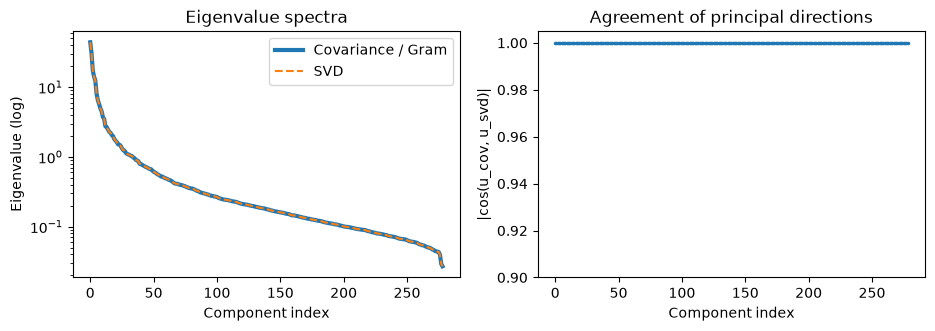

In [9]:
# Compare the two approaches. Eigenvectors are unique only up to sign, so compare |cosine|.
abs_cos = np.abs(np.sum(U_cov * U_svd, axis=0))
rel_eval_diff = np.abs(evals_cov - evals_svd) / evals_svd
k_cmp = 100

comparison = pd.DataFrame({
    "Approach": ["Covariance eigendecomposition (Gram trick)", "SVD of centred data"],
    "Matrix decomposed": [f"G: {n_train} x {n_train}", f"Xc: {n_train} x {D_PIX}"],
    "Time (s)": [t_cov, t_svd],
    "Components obtained": [rank, rank]})
display(comparison)
print(f"Max relative eigenvalue difference (all {rank})    : {rel_eval_diff.max():.2e}")
print(f"Min |cos| between matching directions (top {k_cmp}) : {abs_cos[:k_cmp].min():.10f}")
print(f"Min |cos| between matching directions (all {rank})  : {abs_cos.min():.6f}")

fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
ax[0].semilogy(evals_cov, lw=3, label="Covariance / Gram"); ax[0].semilogy(evals_svd, "--", label="SVD")
ax[0].set_xlabel("Component index"); ax[0].set_ylabel("Eigenvalue (log)"); ax[0].legend()
ax[0].set_title("Eigenvalue spectra")
ax[1].plot(abs_cos, ".", ms=3); ax[1].set_ylim(0.9, 1.005)
ax[1].set_xlabel("Component index"); ax[1].set_ylabel("|cos(u_cov, u_svd)|")
ax[1].set_title("Agreement of principal directions")
fig.savefig(FIG_DIR / "B_covariance_vs_svd.png"); plt.show()

**Comparison.** Both approaches give the same eigenvalues and the same principal directions up to sign (|cos| = 1). Any tiny deviation in the very last components comes from forming $X_c X_c^\top$, which loses precision on the smallest eigenvalues; this is why SVD is the preferred method. On a dataset of this size both are fast; a direct eigendecomposition of the full 10,304 x 10,304 covariance would be far slower and memory-hungry.

From here on the **SVD components** are used. A sign convention (largest-magnitude entry positive) is applied so the eigenfaces are deterministic.

In [10]:
components = Vt[:rank].copy()                           # rows = principal directions (rank x d)
flip = np.sign(components[np.arange(rank), np.abs(components).argmax(axis=1)])
components *= flip[:, None]
eigenvalues = evals_svd

### B.3 Explained variance and choice of the number of components
The variance captured by component $i$ is its eigenvalue $\lambda_i$, and the total variance is $\sum_i \lambda_i = \operatorname{trace}(C) = \lVert X_c \rVert_F^2 /(n-1)$. The explained-variance ratio is $\lambda_i / \sum_j \lambda_j$, and the cumulative curve shows how much variance the first $k$ components keep. We retain the **smallest $k$ with cumulative explained variance $\ge 90\%$**.

Sum of eigenvalues = 246.491119 | trace(C) = 246.491119


,Variance retained,Components needed,"Fraction of 10,304 pixels"
0,80%,40,0.0039
1,90%,92,0.0089
2,95%,149,0.0145
3,99%,236,0.0229


Selected K90 = 92 components (cumulative variance 0.9004)


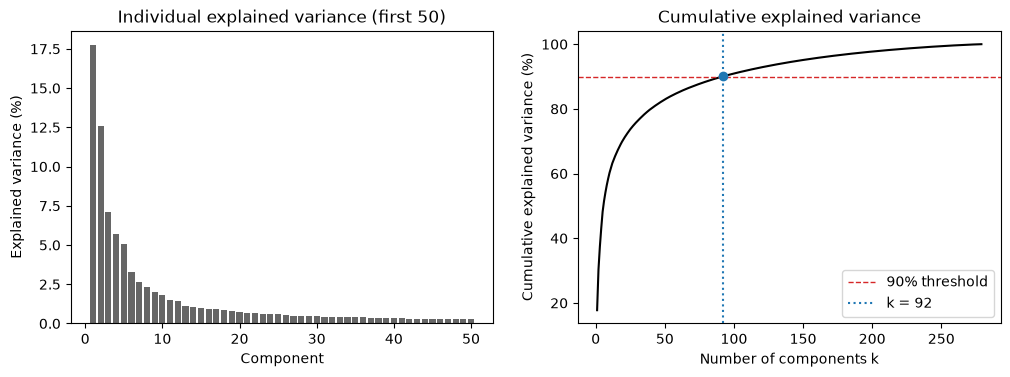

In [11]:
total_var = np.sum(Xc**2) / (n_train - 1)
print(f"Sum of eigenvalues = {eigenvalues.sum():.6f} | trace(C) = {total_var:.6f}")

evr = eigenvalues / eigenvalues.sum()
cum_evr = np.cumsum(evr)
k_for = lambda p: int(np.searchsorted(cum_evr, p) + 1)   # smallest k with cum_evr >= p
K90 = k_for(0.90)

display(pd.DataFrame({"Variance retained": ["80%", "90%", "95%", "99%"],
                      "Components needed": [k_for(p) for p in (0.80, 0.90, 0.95, 0.99)],
                      "Fraction of 10,304 pixels": [k_for(p) / D_PIX for p in (0.80, 0.90, 0.95, 0.99)]}))
print(f"Selected K90 = {K90} components (cumulative variance {cum_evr[K90 - 1]:.4f})")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(np.arange(1, 51), evr[:50] * 100, color="0.4")
ax[0].set_xlabel("Component"); ax[0].set_ylabel("Explained variance (%)")
ax[0].set_title("Individual explained variance (first 50)")
ax[1].plot(np.arange(1, rank + 1), cum_evr * 100, color="k")
ax[1].axhline(90, color="tab:red", ls="--", lw=1, label="90% threshold")
ax[1].axvline(K90, color="tab:blue", ls=":", lw=1.5, label=f"k = {K90}")
ax[1].scatter([K90], [cum_evr[K90 - 1] * 100], color="tab:blue", zorder=3)
ax[1].set_xlabel("Number of components k"); ax[1].set_ylabel("Cumulative explained variance (%)")
ax[1].set_title("Cumulative explained variance"); ax[1].legend(loc="lower right")
fig.savefig(FIG_DIR / "B_explained_variance.png"); plt.show()

### B.4 Eigenfaces
Each principal direction is a vector of 10,304 values, so it can be reshaped to 112 x 92 and shown as an image: an **eigenface**. Gray means zero weight; light and dark regions are pixels that move together (in opposite directions) along that component. The leading eigenfaces capture lighting and coarse face shape; the last ones look like noise and carry very little variance.

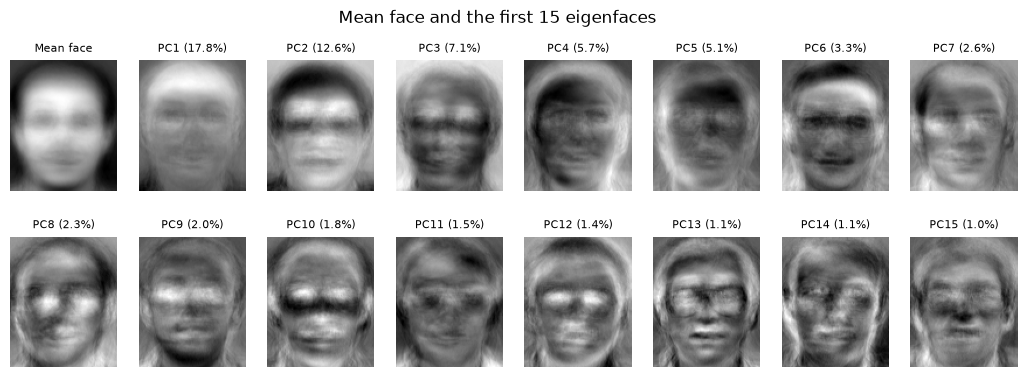

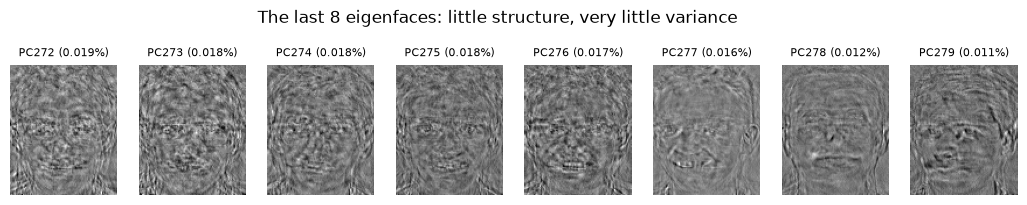

In [12]:
def show_vec(ax, v, title=None, fs=8):
    ax.imshow(v.reshape(IMG_H, IMG_W)); ax.axis("off")
    if title: ax.set_title(title, fontsize=fs)

fig, axes = plt.subplots(2, 8, figsize=(13, 4.2))
show_vec(axes[0, 0], mean_face, "Mean face")
for i, ax in enumerate(axes.ravel()[1:]):
    show_vec(ax, components[i], f"PC{i + 1} ({evr[i] * 100:.1f}%)")
fig.suptitle("Mean face and the first 15 eigenfaces")
fig.savefig(FIG_DIR / "B_eigenfaces.png"); plt.show()

fig, axes = plt.subplots(1, 8, figsize=(13, 2.2))
for ax, i in zip(axes, range(rank - 8, rank)):
    show_vec(ax, components[i], f"PC{i + 1} ({evr[i] * 100:.3f}%)")
fig.suptitle("The last 8 eigenfaces: little structure, very little variance", y=1.04)
fig.savefig(FIG_DIR / "B_last_eigenfaces.png"); plt.show()

### B.5 Projection into PCA space and storage comparison
With $W_k \in \mathbb{R}^{d \times k}$ holding the first $k$ eigenfaces as columns, a face $x$ is represented by $z = W_k^\top (x - \mu) \in \mathbb{R}^{k}$. The training gallery (reduced codes, labels) and the model (mean face, eigenfaces) are saved to `results/pca_model.npz`.

For storage we count values stored as float32 (4 bytes) and compare with the original 8-bit pixels. The PCA model itself (mean + $k$ eigenfaces) is a one-time overhead that is shared by all images.

In [13]:
W = components[:K90].T                         # d x K90
Z_train = (X_train - mean_face) @ W            # n_train x K90
Z_test  = (X_test  - mean_face) @ W            # test images use the training mean
print("Reduced training representation:", Z_train.shape, "| test:", Z_test.shape)

np.savez_compressed(RES_DIR / "pca_model.npz",
                    mean_face=mean_face.astype(np.float32), components=components[:K90].astype(np.float32),
                    Z_train=Z_train.astype(np.float32), y_train=y_train, train_idx=train_idx)

n = n_train
rows = [
    ("Original pixels, uint8 (1 B)",          D_PIX,  n * D_PIX * 1, 0),
    ("Original pixels, float32 (4 B)",        D_PIX,  n * D_PIX * 4, 0),
    (f"PCA codes, k = {K90}, float32",         K90,    n * K90 * 4,   0),
    (f"PCA codes + model (mean + {K90} PCs)", K90,    n * K90 * 4,   (K90 + 1) * D_PIX * 4),
]
storage = pd.DataFrame(rows, columns=["Representation", "Values per image", "Data bytes", "Model bytes"])
storage["Total KB"] = (storage["Data bytes"] + storage["Model bytes"]) / 1024
storage["Ratio vs uint8"] = (n * D_PIX) / (storage["Data bytes"] + storage["Model bytes"])
display(storage)
print(f"Per-image compression vs uint8 pixels: {D_PIX} B -> {K90 * 4} B "
      f"({D_PIX / (K90 * 4):.1f}x smaller)")
print(f"Gallery size at which PCA + model beats raw uint8 storage: "
      f"{int(np.ceil((K90 + 1) * D_PIX * 4 / (D_PIX - 4 * K90)))} images")

Reduced training representation: (280, 92) | test: (120, 92)


,Representation,Values per image,Data bytes,Model bytes,Total KB,Ratio vs uint8
0,"Original pixels, uint8 (1 B)",10304,2885120,0,2817.500,1.000
1,"Original pixels, float32 (4 B)",10304,11540480,0,11270.000,0.250
2,"PCA codes, k = 92, float32",92,103040,0,100.625,28.000
3,PCA codes + model (mean + 92 PCs),92,103040,3833088,3843.875,0.733


Per-image compression vs uint8 pixels: 10304 B -> 368 B (28.0x smaller)
Gallery size at which PCA + model beats raw uint8 storage: 386 images


**Observation.** Each face is described by a few dozen numbers instead of 10,304 pixels. For a small gallery of 280 images the shared model (mean + eigenfaces, in float32) dominates the total, so the overall saving only appears once the gallery is large; the per-image representation, which is what is compared during recognition, is many times smaller.

### B.6 Reconstruction from the reduced representation
A face is reconstructed as $\hat{x} = \mu + W_k z$. We reconstruct **test** faces (unseen when PCA was fitted) for several $k$ and measure quality with the mean squared error (MSE) and the peak signal-to-noise ratio, $\text{PSNR} = 10 \log_{10}(1/\text{MSE})$ dB for pixels in [0, 1].

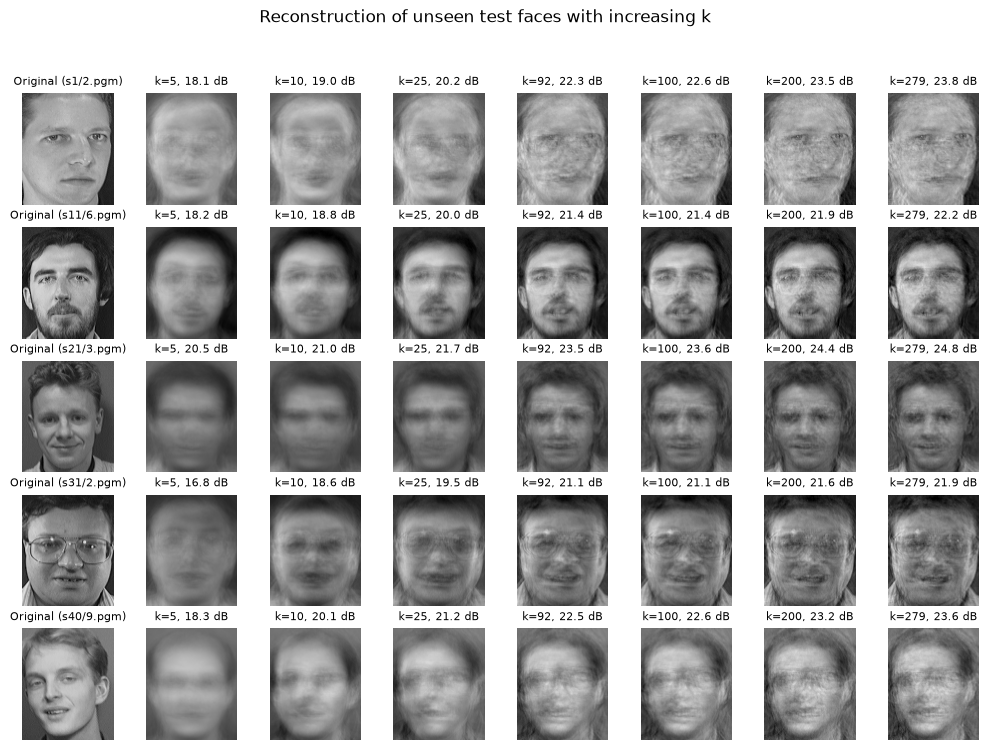

In [14]:
def reconstruct(Xin, k):
    Wk = components[:k].T
    return mean_face + ((Xin - mean_face) @ Wk) @ Wk.T

def mse_psnr(A, B):
    mse = np.mean((A - B) ** 2, axis=1)
    return mse, 10 * np.log10(1.0 / mse)

k_show = [5, 10, 25, K90, 100, 200, rank]
sample = test_idx[[0, 30, 60, 90, 119]]        # five test faces from different subjects
fig, axes = plt.subplots(len(sample), len(k_show) + 1, figsize=(12.5, 8.4))
for r, i in enumerate(sample):
    axes[r, 0].imshow(images[i], vmin=0, vmax=255); axes[r, 0].axis("off")
    axes[r, 0].set_title(f"Original ({paths[i]})", fontsize=8)
    for c, k in enumerate(k_show, start=1):
        rec = reconstruct(X[i:i + 1], k)
        _, p = mse_psnr(rec, X[i:i + 1])
        axes[r, c].imshow(np.clip(rec, 0, 1).reshape(IMG_H, IMG_W), vmin=0, vmax=1)
        axes[r, c].axis("off"); axes[r, c].set_title(f"k={k}, {p[0]:.1f} dB", fontsize=8)
fig.suptitle("Reconstruction of unseen test faces with increasing k")
fig.savefig(FIG_DIR / "B_reconstructions.png"); plt.show()

,k,Cum. var.,Train MSE,Test MSE,Train PSNR (dB),Test PSNR (dB)
0,1,0.1776,1.9604e-02,0.0199,17.2880,17.2352
1,2,0.3034,1.6604e-02,0.0167,17.9906,17.9538
2,5,0.4822,1.2343e-02,0.0128,19.2307,19.0766
3,10,0.6026,9.4728e-03,0.0101,20.3671,20.0647
4,20,0.7055,7.0189e-03,0.0081,21.6746,21.0740
5,30,0.7616,5.6835e-03,0.0071,22.5912,21.6325
6,40,0.8004,4.7571e-03,0.0065,23.3425,22.0238
7,50,0.8292,4.0718e-03,0.0061,24.0074,22.3132
8,60,0.8514,3.5420e-03,0.0058,24.5936,22.5573
9,80,0.8848,2.7470e-03,0.0054,25.6747,22.8987


At K90 = 92: test MSE = 0.00516, test PSNR = 23.07 dB


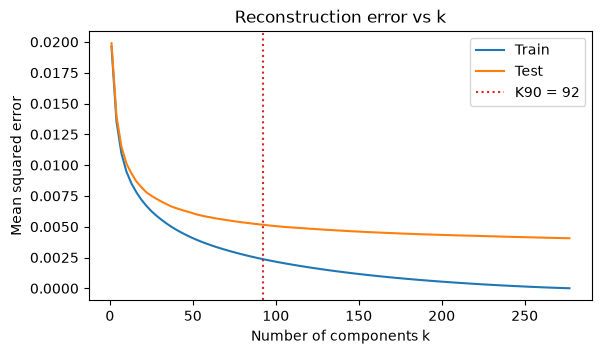

In [15]:
k_grid = [1, 2, 5, 10, 20, 30, 40, 50, 60, 80, 100, 150, 200, rank]
rec_rows = []
for k in k_grid:
    tr_mse, tr_psnr = mse_psnr(reconstruct(X_train, k), X_train)
    te_mse, te_psnr = mse_psnr(reconstruct(X_test, k), X_test)
    rec_rows.append((k, cum_evr[k - 1], tr_mse.mean(), te_mse.mean(), tr_psnr.mean(), te_psnr.mean()))
rec_df = pd.DataFrame(rec_rows, columns=["k", "Cum. var.", "Train MSE", "Test MSE", "Train PSNR (dB)", "Test PSNR (dB)"])
rec_df.to_csv(RES_DIR / "reconstruction_quality.csv", index=False)
display(rec_df)

te_k90 = mse_psnr(reconstruct(X_test, K90), X_test)
print(f"At K90 = {K90}: test MSE = {te_k90[0].mean():.5f}, test PSNR = {te_k90[1].mean():.2f} dB")

fig, ax = plt.subplots(figsize=(6.5, 3.5))
ks = np.arange(1, rank + 1, 3)
ax.plot(ks, [mse_psnr(reconstruct(X_train, k), X_train)[0].mean() for k in ks], label="Train")
ax.plot(ks, [mse_psnr(reconstruct(X_test, k), X_test)[0].mean() for k in ks], label="Test")
ax.axvline(K90, color="tab:red", ls=":", label=f"K90 = {K90}")
ax.set_xlabel("Number of components k"); ax.set_ylabel("Mean squared error"); ax.legend()
ax.set_title("Reconstruction error vs k")
fig.savefig(FIG_DIR / "B_reconstruction_error.png"); plt.show()

**Observation.** Low $k$ gives a blurry, average-looking face; identity-specific details (glasses, hair line, expression) appear as $k$ grows. Training error falls to zero at $k = 279$ because the training faces lie exactly in their own span. Test error levels off instead: part of every new face lies outside the space spanned by the training faces, so it can never be reconstructed exactly. Most of the achievable improvement is already reached around $K_{90}$.

---
## Part C: Recognition in PCA Space

### C.1 Nearest-neighbour matching with Euclidean distance
Each test face is projected with the training mean and eigenfaces, and assigned the label of the **closest stored training face**. Euclidean distance is a natural choice because the eigenfaces are orthonormal: the distance between two PCA codes equals the distance between their reconstructions in pixel space, $\lVert z_a - z_b \rVert = \lVert \hat{x}_a - \hat{x}_b \rVert$, so matching in PCA space is matching in a denoised pixel space.

Distances are computed in a vectorised way using $\lVert a-b \rVert^2 = \lVert a \rVert^2 + \lVert b \rVert^2 - 2a^\top b$. The square root is not needed to find the minimum, so it is applied only to report the distance.

In [16]:
def pairwise_sq_euclidean(A, B):
    sq = (A**2).sum(1)[:, None] + (B**2).sum(1)[None, :] - 2.0 * A @ B.T
    return np.maximum(sq, 0.0)                      # clip tiny negatives from rounding

def pairwise_cosine_distance(A, B):
    An = A / np.linalg.norm(A, axis=1, keepdims=True)
    Bn = B / np.linalg.norm(B, axis=1, keepdims=True)
    return 1.0 - An @ Bn.T

def nearest_neighbour(train_feats, train_labels, test_feats, metric="euclidean"):
    Dm = (pairwise_sq_euclidean if metric == "euclidean" else pairwise_cosine_distance)(test_feats, train_feats)
    nn = Dm.argmin(axis=1)
    d = Dm[np.arange(len(nn)), nn]
    return train_labels[nn], nn, (np.sqrt(d) if metric == "euclidean" else d)

# Sanity check of the distance identity on two test faces
za, zb = Z_test[0], Z_test[1]
xa, xb = reconstruct(X_test[:1], K90)[0], reconstruct(X_test[1:2], K90)[0]
print(f"||za - zb|| = {np.linalg.norm(za - zb):.6f}   ||xa_hat - xb_hat|| = {np.linalg.norm(xa - xb):.6f}")

t0 = time.perf_counter()
pred_pca, nn_pca, dist_pca = nearest_neighbour(Z_train, y_train, Z_test)
t_pca = time.perf_counter() - t0
acc_pca = np.mean(pred_pca == y_test)
print(f"PCA (k = {K90}) + 1-NN Euclidean accuracy: {acc_pca:.4f} "
      f"({np.sum(pred_pca == y_test)}/{len(y_test)})")

||za - zb|| = 18.983725   ||xa_hat - xb_hat|| = 18.983725
PCA (k = 92) + 1-NN Euclidean accuracy: 0.9750 (117/120)


### C.2 Baseline: matching on raw pixels
The same nearest-neighbour rule is applied to the full 10,304-dimensional pixel vectors, to see what PCA costs or gains in accuracy, speed and memory.

In [17]:
t0 = time.perf_counter()
pred_raw, nn_raw, dist_raw = nearest_neighbour(X_train, y_train, X_test)
t_raw = time.perf_counter() - t0
acc_raw = np.mean(pred_raw == y_test)

raw_vs_pca = pd.DataFrame({
    "Representation": ["Raw pixels", f"PCA (k = {K90}, 90% variance)"],
    "Dimensions": [D_PIX, K90],
    "Gallery size (KB, float32)": [n_train * D_PIX * 4 / 1024, n_train * K90 * 4 / 1024],
    "Matching time, 120 queries (ms)": [t_raw * 1e3, t_pca * 1e3],
    "Accuracy": [acc_raw, acc_pca]})
display(raw_vs_pca)
print("Test images where the two methods disagree:", np.sum(pred_raw != pred_pca))

,Representation,Dimensions,"Gallery size (KB, float32)","Matching time, 120 queries (ms)",Accuracy
0,Raw pixels,10304,11270.000,38.3113,0.975
1,"PCA (k = 92, 90% variance)",92,100.625,5.5332,0.975


Test images where the two methods disagree: 2


### C.3 Inspecting correct and incorrect matches
Each row shows the test image, the training face it was matched to, and (for errors) a training image of the true subject.

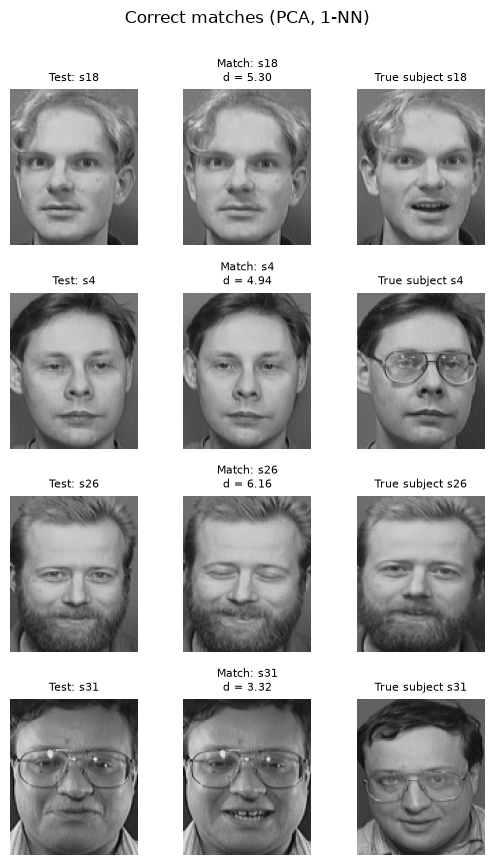

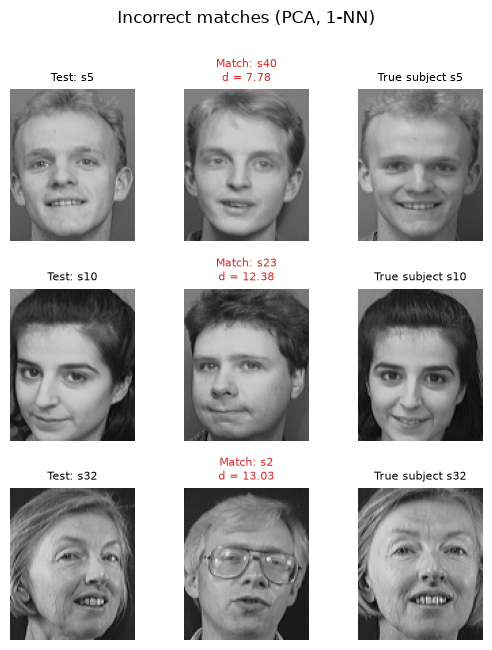

Mean NN distance, correct: 6.53 | incorrect: 11.06


In [18]:
def show_matches(idx_list, title, fname):
    if len(idx_list) == 0:
        print(f"No cases for: {title}"); return
    fig, axes = plt.subplots(len(idx_list), 3, figsize=(5.4, 2.15 * len(idx_list)), squeeze=False)
    for r, j in enumerate(idx_list):
        t_i, m_i = test_idx[j], train_idx[nn_pca[j]]
        true_i = train_idx[np.flatnonzero(y_train == y_test[j])[0]]
        ok = pred_pca[j] == y_test[j]
        for c, (img_i, ttl) in enumerate([(t_i, f"Test: s{y_test[j]}"),
                                           (m_i, f"Match: s{pred_pca[j]}\nd = {dist_pca[j]:.2f}"),
                                           (true_i, f"True subject s{y_test[j]}")]):
            axes[r, c].imshow(images[img_i], vmin=0, vmax=255); axes[r, c].axis("off")
            axes[r, c].set_title(ttl, fontsize=8, color=("k" if ok or c != 1 else "tab:red"))
    fig.suptitle(title, y=1.0); fig.tight_layout()
    fig.savefig(FIG_DIR / fname); plt.show()

correct = np.flatnonzero(pred_pca == y_test)
wrong = np.flatnonzero(pred_pca != y_test)
rng = np.random.default_rng(SEED)
show_matches(rng.choice(correct, 4, replace=False), "Correct matches (PCA, 1-NN)", "C_correct_matches.png")
show_matches(wrong[:6], "Incorrect matches (PCA, 1-NN)", "C_incorrect_matches.png")

print(f"Mean NN distance, correct: {dist_pca[correct].mean():.2f} | incorrect: {dist_pca[wrong].mean():.2f}")

**Observation.** Only 3 of 120 test faces are misidentified. Two of the errors (subjects 10 and 32) are test images with a strong head tilt or rotation that none of the subject's training images share, so a different person photographed at a similar angle ends up closer in pixel space. The third (subject 5 matched to subject 40) involves two young men with similar hair, face shape and lighting. Incorrect matches also have clearly larger nearest-neighbour distances on average than correct ones, so a distance threshold could be used to flag uncertain matches or reject unknown people.

### C.4 Effect of the number of components and of the distance measure
To see how compact the representation can be, the 1-NN accuracy is computed for a range of $k$, with Euclidean and cosine distance (cosine ignores the overall length of the code, i.e. global contrast). This is an exploratory analysis on the test set; proper model selection with cross-validation is done in Part D.

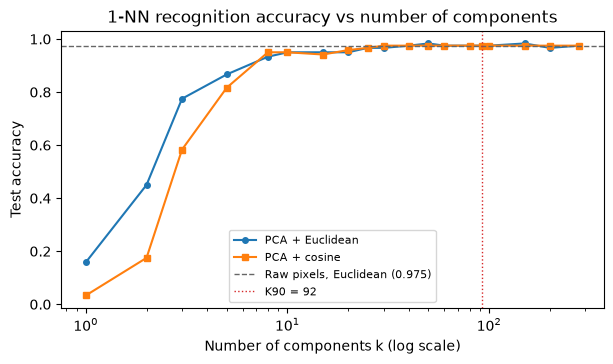

Raw pixels with cosine distance: 0.9500


k,1,2,3,5,8,10,15,20,25,30,40,50,60,80,92,100,150,200,279
Euclidean,0.1583,0.450,0.7750,0.8667,0.9333,0.95,0.9500,0.9500,0.9667,0.9667,0.975,0.9833,0.975,0.975,0.975,0.975,0.9833,0.9667,0.975
Cosine,0.0333,0.175,0.5833,0.8167,0.9500,0.95,0.9417,0.9583,0.9667,0.9750,0.975,0.9750,0.975,0.975,0.975,0.975,0.9750,0.9750,0.975


In [19]:
k_list = [1, 2, 3, 5, 8, 10, 15, 20, 25, 30, 40, 50, 60, 80, 100, 150, 200, rank]
if K90 not in k_list: k_list = sorted(k_list + [K90])
Z_tr_all = (X_train - mean_face) @ components.T
Z_te_all = (X_test  - mean_face) @ components.T
acc_k = {m: [np.mean(nearest_neighbour(Z_tr_all[:, :k], y_train, Z_te_all[:, :k], m)[0] == y_test)
             for k in k_list] for m in ("euclidean", "cosine")}
acc_k_df = pd.DataFrame({"k": k_list, "Euclidean": acc_k["euclidean"], "Cosine": acc_k["cosine"]})
acc_k_df.to_csv(RES_DIR / "nn_accuracy_vs_k.csv", index=False)

acc_raw_cos = np.mean(nearest_neighbour(X_train, y_train, X_test, "cosine")[0] == y_test)
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.plot(k_list, acc_k["euclidean"], "o-", ms=4, label="PCA + Euclidean")
ax.plot(k_list, acc_k["cosine"], "s-", ms=4, label="PCA + cosine")
ax.axhline(acc_raw, color="0.4", ls="--", lw=1, label=f"Raw pixels, Euclidean ({acc_raw:.3f})")
ax.axvline(K90, color="tab:red", ls=":", lw=1, label=f"K90 = {K90}")
ax.set_xscale("log"); ax.set_xlabel("Number of components k (log scale)"); ax.set_ylabel("Test accuracy")
ax.set_title("1-NN recognition accuracy vs number of components"); ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "C_accuracy_vs_k.png"); plt.show()
print(f"Raw pixels with cosine distance: {acc_raw_cos:.4f}")
acc_k_df.set_index("k").T

**Observation.** Accuracy climbs from about 16% with one component to 95% with only 10 components. From about 40 components the PCA baseline equals the raw-pixel accuracy (97.5%) while using less than 0.4% of the dimensions and matching roughly 30 times faster. Beyond that the curve is flat; changes of one image (0.83 points) are within noise. Cosine distance is worse for very small $k$ (where the length of the code carries useful information) and equivalent afterwards, so Euclidean distance is kept as the baseline. The 90%-variance rule ($k = 92$) is therefore safe but more generous than recognition needs.

---
## Part D: Traditional Machine Learning on PCA Features

### D.1 Wrapping the NumPy PCA as a pipeline step
To tune the number of components fairly, PCA must be **re-fitted inside every cross-validation fold** (otherwise the validation images would influence the eigenfaces). The NumPy PCA from Part B is therefore wrapped in a small class with the Scikit-learn `fit` / `transform` interface. All the mathematics stays in NumPy; Scikit-learn only provides the plumbing (pipelines and grid search).

- `fit` uses the Gram-matrix eigendecomposition from B.2, which was shown to match SVD and is several times faster when $n \ll d$ (important because it runs hundreds of times during the grid search).
- `whiten=True` divides each code by $\sqrt{\lambda_i}$, giving every component unit variance. On PCA codes this is the same as standardisation, so no separate scaler is needed; whitening is tuned as a hyperparameter because it helps some classifiers and hurts others.

In [20]:
from sklearn.base import BaseEstimator, TransformerMixin

class NumpyPCA(BaseEstimator, TransformerMixin):
    # PCA implemented with NumPy (Gram-matrix eigendecomposition), Scikit-learn compatible.
    def __init__(self, n_components=50, whiten=False):
        self.n_components = n_components
        self.whiten = whiten

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = X.mean(axis=0)
        Xc = X - self.mean_
        n = X.shape[0]
        evals, evecs = np.linalg.eigh(Xc @ Xc.T / (n - 1))
        order = np.argsort(evals)[::-1][: min(self.n_components, n - 1)]
        U = Xc.T @ evecs[:, order]
        self.components_ = (U / np.linalg.norm(U, axis=0)).T
        self.explained_variance_ = evals[order]
        return self

    def transform(self, X):
        Z = (np.asarray(X, dtype=np.float64) - self.mean_) @ self.components_.T
        return Z / np.sqrt(self.explained_variance_) if self.whiten else Z

# Check: same subspace as the Part B SVD components
chk = NumpyPCA(K90).fit(X_train)
print("Min |cos| with Part B components:", np.abs(np.sum(chk.components_ * components[:K90], axis=1)).min())

Min |cos| with Part B components: 0.999999999999997


### D.2 Classifiers, hyperparameters and validation protocol

| Model | Why it is included | Hyperparameters tuned |
|---|---|---|
| **KNN** | Direct generalisation of the Part C baseline (1-NN Euclidean is a special case) | neighbours, uniform / distance weighting, Euclidean / cosine metric |
| **Logistic Regression** | Linear, probabilistic, multinomial classifier; L2 regularisation controls overfitting with only 7 images per class | inverse regularisation strength `C` |
| **Linear SVM** | Maximum-margin linear classifier; works well when samples are few relative to features | `C` |
| **RBF SVM** | Non-linear decision boundaries via a Gaussian kernel | `C`, `gamma` |

For every model the grid also includes the **number of PCA components** and **whitening**. Selection uses **5-fold stratified cross-validation on the training set only**; the test set is used exactly once, to evaluate the selected configuration. Accuracy is the metric because the classes are perfectly balanced.

In [21]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
pca_grid = {"pca__n_components": sorted({10, 20, 30, K90, 80, 120}), "pca__whiten": [False, True]}

models = {
    "KNN": (KNeighborsClassifier(),
            {"clf__n_neighbors": [1, 3, 5], "clf__weights": ["uniform", "distance"],
             "clf__metric": ["euclidean", "cosine"]}),
    "Logistic Regression": (LogisticRegression(max_iter=5000),
            {"clf__C": [0.01, 0.1, 1, 10, 100]}),
    "Linear SVM": (SVC(kernel="linear"),
            {"clf__C": [0.001, 0.01, 0.1, 1, 10]}),
    "RBF SVM": (SVC(kernel="rbf"),
            {"clf__C": [1, 10, 100, 1000], "clf__gamma": ["scale", 0.001, 0.01]}),
}

searches = {}
for name, (clf, grid) in models.items():
    pipe = Pipeline([("pca", NumpyPCA()), ("clf", clf)])
    gs = GridSearchCV(pipe, {**pca_grid, **grid}, cv=cv, scoring="accuracy", n_jobs=-1, refit=True)
    t0 = time.perf_counter(); gs.fit(X_train, y_train)
    searches[name] = (gs, time.perf_counter() - t0)
    print(f"{name:20s} best CV acc = {gs.best_score_:.4f}  ({len(gs.cv_results_['params'])} settings, "
          f"{searches[name][1]:.0f} s)")

KNN                  best CV acc = 0.9393  (144 settings, 26 s)
Logistic Regression  best CV acc = 0.9607  (60 settings, 9 s)
Linear SVM           best CV acc = 0.9607  (60 settings, 8 s)
RBF SVM              best CV acc = 0.9607  (144 settings, 17 s)


### D.3 Comparison with the similarity-based baseline
The baselines from Part C are evaluated with the same cross-validation folds, so all rows of the table are directly comparable.

In [23]:
def evaluate(pipe):
    t0 = time.perf_counter(); pipe.fit(X_train, y_train); fit_t = time.perf_counter() - t0
    t0 = time.perf_counter(); acc = np.mean(pipe.predict(X_test) == y_test); pred_t = time.perf_counter() - t0
    return acc, fit_t, pred_t

rows = []
# Baseline 1: 1-NN on raw pixels (identity "PCA" not applied)
raw_pipe = Pipeline([("clf", KNeighborsClassifier(n_neighbors=1))])
cv_raw = cross_val_score(raw_pipe, X_train, y_train, cv=cv).mean()
rows.append(("1-NN Euclidean, raw pixels (baseline)", D_PIX, "-", cv_raw, *evaluate(raw_pipe)))
# Baseline 2: 1-NN on PCA (K90), as in Part C
base_pipe = Pipeline([("pca", NumpyPCA(K90)), ("clf", KNeighborsClassifier(n_neighbors=1))])
cv_base = cross_val_score(base_pipe, X_train, y_train, cv=cv).mean()
rows.append((f"1-NN Euclidean, PCA k = {K90} (baseline)", K90, "-", cv_base, *evaluate(base_pipe)))

for name, (gs, _) in searches.items():
    bp = gs.best_params_
    params = ", ".join(f"{k.split('__')[1]}={v}" for k, v in bp.items() if not k.startswith("pca"))
    acc, fit_t, pred_t = evaluate(gs.best_estimator_)
    rows.append((name, bp["pca__n_components"], f"whiten={bp['pca__whiten']}; {params}",
                 gs.best_score_, acc, fit_t, pred_t))

results = pd.DataFrame(rows, columns=["Method", "Features", "Selected settings", "CV accuracy",
                                      "Test accuracy", "Fit time (s)", "Predict time (s)"])
results.to_csv(RES_DIR / "ml_comparison.csv", index=False)
with open(RES_DIR / "ml_comparison.md", "w") as f:
    f.write(results.to_markdown(index=False, floatfmt=".4f"))
results

d:\Daiict 1st sem\FOML LAB\202618052_LakshitaPagaria_DS605\.venv\Lib\site-packages\sklearn\metrics\_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, input_name="y_true")
d:\Daiict 1st sem\FOML LAB\202618052_LakshitaPagaria_DS605\.venv\Lib\site-packages\sklearn\metrics\_classification.py:99: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_pred = type_of_target(y_pred, input_name="y_pred")
d:\Daiict 1st sem\FOML LAB\202618052_LakshitaPagaria_DS605\.venv\Lib\site-packages\sklearn\metrics\_classification.py:98: UserWarning: The number of unique classes is greater than 50% of the number of samples. `y` could represent a regression problem, not a classification problem.
  type_true = type_of_target(y_true, i

,Method,Features,Selected settings,CV accuracy,Test accuracy,Fit time (s),Predict time (s)
0,"1-NN Euclidean, raw pixels (baseline)",10304,-,0.9393,0.9750,0.0034,0.0311
1,"1-NN Euclidean, PCA k = 92 (baseline)",92,-,0.9357,0.9750,0.0743,0.0133
2,KNN,30,"whiten=False; metric=cosine, n_neighbors=1, weights=uniform",0.9393,0.9750,0.0614,0.0071
3,Logistic Regression,30,whiten=False; C=1,0.9607,0.9750,0.1023,0.0047
4,Linear SVM,92,whiten=False; C=0.1,0.9607,0.9833,0.0794,0.0088
5,RBF SVM,80,"whiten=False; C=10, gamma=0.001",0.9607,0.9833,0.0825,0.0148


### D.4 Number of retained components vs accuracy
For each classifier, the best cross-validated accuracy at each number of components (taking the best of its other settings) shows how compact the representation can be before accuracy drops.

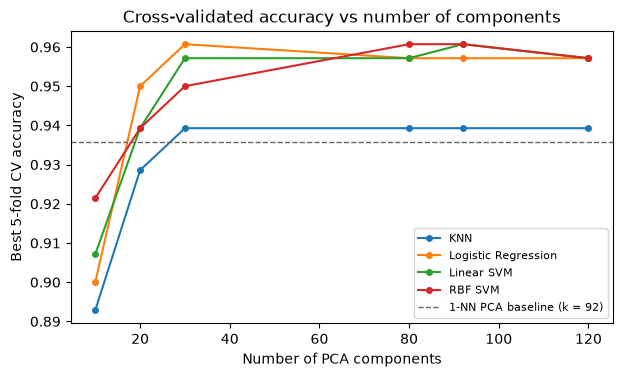

param_pca__n_components,10,20,30,80,92,120
KNN,0.8929,0.9286,0.9393,0.9393,0.9393,0.9393
Logistic Regression,0.9000,0.9500,0.9607,0.9571,0.9571,0.9571
Linear SVM,0.9071,0.9393,0.9571,0.9571,0.9607,0.9571
RBF SVM,0.9214,0.9393,0.9500,0.9607,0.9607,0.9571


,"Best CV acc, whiten=False","Best CV acc, whiten=True"
KNN,0.9393,0.9286
Logistic Regression,0.9607,0.9393
Linear SVM,0.9607,0.9429
RBF SVM,0.9607,0.9464


In [24]:
fig, ax = plt.subplots(figsize=(7, 3.8))
summary = {}
for name, (gs, _) in searches.items():
    cvr = pd.DataFrame(gs.cv_results_)
    best_per_k = cvr.groupby("param_pca__n_components")["mean_test_score"].max()
    summary[name] = best_per_k
    ax.plot(best_per_k.index.astype(int), best_per_k.values, "o-", ms=4, label=name)
ax.axhline(cv_base, color="0.4", ls="--", lw=1, label=f"1-NN PCA baseline (k = {K90})")
ax.set_xlabel("Number of PCA components"); ax.set_ylabel("Best 5-fold CV accuracy")
ax.set_title("Cross-validated accuracy vs number of components"); ax.legend(fontsize=8)
fig.savefig(FIG_DIR / "D_cv_accuracy_vs_components.png"); plt.show()

whiten_effect = pd.DataFrame({
    name: pd.DataFrame(gs.cv_results_).groupby("param_pca__whiten")["mean_test_score"].max()
    for name, (gs, _) in searches.items()}).T
whiten_effect.columns = ["Best CV acc, whiten=False", "Best CV acc, whiten=True"]
display(pd.DataFrame(summary).T.round(4))
whiten_effect

### D.5 Stability across different train-test splits
With 120 test images, one misclassification changes accuracy by 0.83 percentage points, so differences between models on a single split can be noise. Each selected configuration is therefore re-evaluated on 10 further random stratified 7/3 splits (seeds 0-9), refitting PCA each time.

In [25]:
from sklearn.base import clone

final_pipes = {"1-NN raw pixels": raw_pipe, f"1-NN PCA k={K90}": base_pipe}
final_pipes.update({name: gs.best_estimator_ for name, (gs, _) in searches.items()})

rep = {name: [] for name in final_pipes}
for s in range(10):
    tr, te = stratified_split(y, N_TRAIN_PER_SUBJECT, s)
    for name, p in final_pipes.items():
        m = clone(p).fit(X[tr], y[tr])
        rep[name].append(np.mean(m.predict(X[te]) == y[te]))

stability = pd.DataFrame({"Mean test accuracy": {k: np.mean(v) for k, v in rep.items()},
                          "Std": {k: np.std(v) for k, v in rep.items()},
                          "Min": {k: np.min(v) for k, v in rep.items()},
                          "Max": {k: np.max(v) for k, v in rep.items()}})
stability.to_csv(RES_DIR / "stability_10_splits.csv")
stability

,Mean test accuracy,Std,Min,Max
1-NN raw pixels,0.9675,0.0108,0.9500,0.9833
1-NN PCA k=92,0.9708,0.0107,0.9583,0.9917
KNN,0.9725,0.0112,0.9583,0.9917
Logistic Regression,0.9800,0.0100,0.9667,1.0000
Linear SVM,0.9858,0.0084,0.9750,1.0000
RBF SVM,0.9858,0.0084,0.9750,1.0000


**Observation.** Across 10 random splits all PCA-based methods are at least as accurate as raw-pixel matching. The SVMs and Logistic Regression are consistently ahead of nearest-neighbour matching, by roughly one to one and a half percentage points on average, which is about one standard deviation, so the gain is real but modest on this easy, well-aligned dataset.

---
## Summary and Conclusions

**Representation and PCA (Parts A, B)**
- Each 112 x 92 grayscale image becomes a 10,304-dimensional vector; the 400 x 10,304 image matrix with labels was split 7/3 per subject (280 / 120) with a fixed seed.
- Covariance eigendecomposition (via the 280 x 280 Gram matrix) and SVD produced identical eigenvalues and principal directions up to sign. SVD is preferred for numerical stability; the Gram route is faster when there are far fewer images than pixels.
- 92 components (0.9% of the original dimensions) retain 90% of the training variance; 40 retain 80%.
- Each face is stored with 92 numbers instead of 10,304 pixels (28x smaller per image). The shared model (mean face and eigenfaces) only pays for itself once the gallery exceeds about 386 images.
- Reconstructions at $k = 92$ reach about 23 dB PSNR on unseen faces. Test reconstruction error plateaus because new faces are not fully contained in the span of the training faces.

**Recognition (Parts C, D)**
- 1-NN matching with Euclidean distance in PCA space achieves 97.5% test accuracy, the same as raw pixels, with a 112x smaller gallery and much faster matching. Roughly 40 components already give the same accuracy, and 10 give 95%.
- Errors are mainly caused by pose (head tilt and rotation) that is not covered by the training images.
- Linear SVM and RBF SVM reach 98.3% on the main split and 98.6% averaged over 10 splits, the best of all methods; Logistic Regression is close behind. Cross-validation shows accuracy saturates between 30 and 90 components for every classifier.
- Whitening reduced cross-validated accuracy for every model: it gives the noisy low-variance components the same weight as the informative leading ones.

**Overall.** PCA gives a compact, fast and equally accurate face representation, and a regularised linear classifier on 30 to 90 PCA features is the best accuracy-to-size trade-off in these experiments.

**Limitations.** ORL is small and the faces are well aligned with uniform backgrounds, so results are optimistic compared with real-world conditions. PCA is unsupervised and keeps directions of maximum variance (often lighting), not of maximum class separation; a supervised projection such as LDA (Fisherfaces) would be a natural next step.